# 03 · Revenue lost to the referral program

**Question:** What is the total amount of revenue lost due to our referral program? Should we continue to offer discounts for referred customers?

**Short answer:** **Net revenue lost: $21,325** over 2024–2025. That's $22,189 in referral discounts on 3,563 first orders, less $863 of extra shipping the discount caused, or about **$6 per referred customer**. **Yes, keep the discount:** referred customers are almost as valuable as everyone else ($324 profit per active buyer, against $332).

**Business rules (from the challenge brief)**
- **Referral:** referred customers get **10% off their first order**.
- **Black Friday:** **20% off** every order placed on Black Friday, by the customer's local date (Nov 29, 2024; Nov 28, 2025). It's applied before the referral discount.
- **Shipping charged to the customer:** $7.99 under $50, $4.99 from $50 to $99.99, free from $100 (based on the item total after discounts).
- **Carrier fee:** the company pays $4.99 per order.

**Approach**
- **Delivered orders only** (`is_revenue`), lines with a valid quantity. Item revenue = quantity × catalog price.
- **First order = a buyer's earliest delivered order**, by the order time in the buyer's local time.
- **Revenue lost = the referral discount, minus the extra shipping it caused.** A discount can push an order below $50 or $100, so the customer pays a higher shipping fee. That extra shipping offsets part of the discount.
- **Profit per order = item profit − discounts + shipping charged − carrier fee**, where item profit = item revenue × profit margin.

## 1. Setup

In [1]:
import os, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Project folder: same location as the cleaning notebook
USE_DRIVE = True
IN_COLAB = "google.colab" in sys.modules

if IN_COLAB and USE_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
    BASE = "/content/drive/MyDrive/ecommerce-challenge"
elif IN_COLAB:
    BASE = "/content/ecommerce-challenge"
else:
    BASE = os.path.abspath("ecommerce-challenge")

CLEAN = os.path.join(BASE, "data", "clean")
pd.set_option("display.max_columns", 30, "display.width", 160)

# Business rules from the brief
REFERRAL_DISCOUNT = 0.10
BLACK_FRIDAY_DISCOUNT = 0.20
BLACK_FRIDAYS = pd.to_datetime(["2024-11-29", "2025-11-28"])   # add a date if the data covers more years
CARRIER_FEE = 4.99


def shipping_charged(item_total):
    # $7.99 under $50, $4.99 from $50 to $99.99, free from $100
    return np.select([item_total < 50, item_total < 100], [7.99, 4.99], 0.0)

Mounted at /content/drive


## 2. Load data

In [3]:
customers = pd.read_csv(os.path.join(CLEAN, "customers.csv"), dtype=str)
products = pd.read_csv(os.path.join(CLEAN, "products.csv"), dtype={"sku_id": str})
sales = pd.read_csv(os.path.join(CLEAN, "sales.csv"), dtype=str)

# CSV files store everything as text: restore the types we need
customers["is_referred"] = pd.to_numeric(customers.is_referred).astype("Int64")   # 1 / 0 / NA (unknown)
sales["quantity"] = pd.to_numeric(sales.quantity)
sales["is_revenue"] = sales.is_revenue.eq("True")
sales["order_datetime"] = pd.to_datetime(sales.order_datetime)                     # buyer's local time

## 3. Build one row per delivered order

Each order gets its list price, Black Friday discount, referral discount, shipping and profit.

In [4]:
# Delivered lines with a valid quantity, with price and margin attached
lines = sales[sales.is_revenue & sales.quantity.notna()].merge(
    products[["sku_id", "price", "profit_margin"]], on="sku_id", how="left")
assert lines.price.notna().all(), "some sales lines have no matching product"
lines["list_revenue"] = lines.quantity * lines.price
lines["item_profit"] = lines.list_revenue * lines.profit_margin

# One row per order
orders = lines.groupby("order_id").agg(
    buyer_id=("buyer_id", "first"),
    order_time=("order_datetime", "min"),
    list_revenue=("list_revenue", "sum"),
    item_profit=("item_profit", "sum"),
).reset_index()

# Black Friday: 20% off, by the buyer's local date (applied first)
orders["is_black_friday"] = orders.order_time.dt.normalize().isin(BLACK_FRIDAYS)
orders["black_friday_discount"] = np.where(orders.is_black_friday, orders.list_revenue * BLACK_FRIDAY_DISCOUNT, 0.0)
orders["pre_referral_total"] = orders.list_revenue - orders.black_friday_discount

# First delivered order per buyer (ties broken by order_id)
orders = orders.sort_values(["order_time", "order_id"])
has_buyer = orders.buyer_id.notna() & orders.order_time.notna()
orders["order_rank"] = orders[has_buyer].groupby("buyer_id").cumcount() + 1

# Referral: 10% off the first order of a referred buyer
orders = orders.merge(customers[["buyer_id", "is_referred"]], on="buyer_id", how="left")
orders["is_referral_order"] = orders.order_rank.eq(1) & orders.is_referred.eq(1).fillna(False)
orders["referral_discount"] = np.where(orders.is_referral_order, orders.pre_referral_total * REFERRAL_DISCOUNT, 0.0)
orders["item_total"] = orders.pre_referral_total - orders.referral_discount

# Shipping, with and without the referral discount
orders["shipping"] = shipping_charged(orders.item_total)
orders["shipping_without_referral"] = shipping_charged(orders.pre_referral_total)

# Order revenue and profit
orders["total_revenue"] = orders.item_total + orders.shipping
orders["profit"] = (orders.item_profit - orders.black_friday_discount - orders.referral_discount
                    + orders.shipping - CARRIER_FEE)

print(f"{len(orders):,} delivered orders; {orders.is_referral_order.sum():,} were a referred buyer's first order")

235,228 delivered orders; 3,563 were a referred buyer's first order


## 4. Revenue lost to the referral discount

In [5]:
ref = orders[orders.is_referral_order].copy()
ref["extra_shipping"] = ref.shipping - ref.shipping_without_referral


lost = pd.Series({
    "Referred buyers' first orders": f"{len(ref):,}",
    "Referral discount given": f"${ref.referral_discount.sum():,.2f}",
    "Less: extra shipping the discount caused": f"${ref.extra_shipping.sum():,.2f}",
    "Net revenue lost": f"${ref.referral_discount.sum() - ref.extra_shipping.sum():,.2f}",
    "Average discount per referred customer": f"${ref.referral_discount.mean():.2f}",
}, name="2024–2025").to_frame()
lost

,2024–2025
Referred buyers' first orders,"3,563"
Referral discount given,"$22,188.76"
Less: extra shipping the discount caused,$863.37
Net revenue lost,"$21,325.39"
Average discount per referred customer,$6.23


## 5. Do referred first orders still make money?

Small orders are where a discount hurts most: they also pay the highest shipping tier and still carry the $4.99 carrier fee.

In [6]:
ref["order_size"] = pd.cut(ref.pre_referral_total, [0, 50, 100, np.inf], right=False,
                           labels=["Under $50", "$50–99.99", "$100 and up"])

by_size = ref.groupby("order_size", observed=True).agg(
    orders=("order_id", "size"),
    referral_discount=("referral_discount", "sum"),
    avg_profit=("profit", "mean"),
    losing_money=("profit", lambda p: (p < 0).mean()),
)
by_size.loc["All referred first orders"] = [
    len(ref), ref.referral_discount.sum(), ref.profit.mean(), (ref.profit < 0).mean()]
by_size.index.name = "Order size (before referral discount)"
by_size.style.format({"orders": "{:,.0f}", "referral_discount": "${:,.0f}",
                      "avg_profit": "${:.2f}", "losing_money": "{:.1%}"})

,orders,referral_discount,avg_profit,losing_money
Order size (before referral discount),,,,
Under $50,"2,273","$4,806",$8.60,3.4%
$50–99.99,761,"$5,202",$16.13,8.1%
$100 and up,529,"$12,181",$88.98,6.2%
All referred first orders,"3,563","$22,189",$22.14,4.9%


## 6. Are referred customers worth it?

Compares every customer by referral status. **Active** = at least one delivered order in 2024–2025. Revenue and profit include discounts, shipping and the carrier fee.

In [7]:
buyer_value = orders.dropna(subset=["buyer_id"]).groupby("buyer_id").agg(
    orders=("order_id", "size"),
    revenue=("total_revenue", "sum"),
    profit=("profit", "sum"),
)

cust = customers[["buyer_id", "is_referred"]].merge(buyer_value, on="buyer_id", how="left")
cust["cohort"] = cust.is_referred.map({1: "Referred", 0: "Not referred"}).fillna("Unknown")

cohorts = cust.groupby("cohort").agg(
    customers=("buyer_id", "size"),
    active_buyers=("orders", "count"),
    orders_per_active_buyer=("orders", "mean"),
    revenue=("revenue", "sum"),
    total_orders=("orders", "sum"),
    revenue_per_active_buyer=("revenue", "mean"),
    profit_per_active_buyer=("profit", "mean"),
)
cohorts["active_pct"] = cohorts.active_buyers / cohorts.customers
cohorts["avg_order_value"] = cohorts.revenue / cohorts.total_orders
cohorts = cohorts[["customers", "active_pct", "orders_per_active_buyer", "avg_order_value",
                   "revenue_per_active_buyer", "profit_per_active_buyer"]].loc[["Referred", "Not referred", "Unknown"]]
cohorts.index.name = "Cohort"

cohorts.style.format({"customers": "{:,}", "active_pct": "{:.1%}", "orders_per_active_buyer": "{:.2f}",
                      "avg_order_value": "${:.2f}", "revenue_per_active_buyer": "${:,.2f}",
                      "profit_per_active_buyer": "${:,.2f}"})

,customers,active_pct,orders_per_active_buyer,avg_order_value,revenue_per_active_buyer,profit_per_active_buyer
Cohort,,,,,,
Referred,"6,984",51.0%,9.46,$82.86,$783.62,$323.61
Not referred,"40,043",50.0%,9.39,$85.25,$800.56,$332.12
Unknown,473,45.2%,9.09,$77.22,$702.18,$286.95


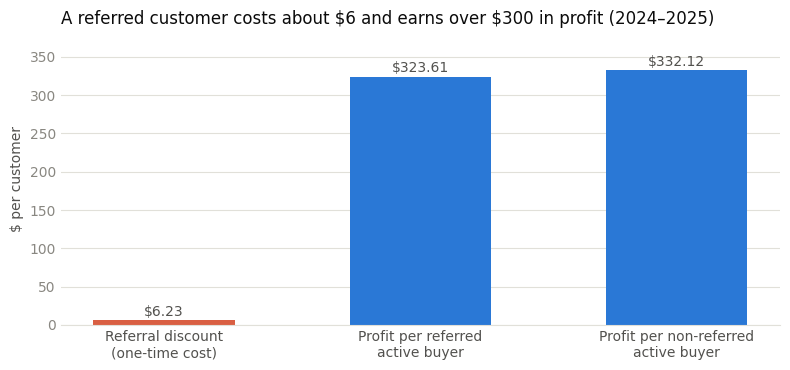

In [8]:
# Chart: what a referred customer costs vs what they bring in
BLUE, INK, MUTED, GRID, CORAL = "#2a78d6", "#52514e", "#898781", "#e1e0d9", "#d95f43"

cost = ref.referral_discount.mean()
values = pd.Series({
    "Referral discount\n(one-time cost)": cost,
    "Profit per referred\nactive buyer": cohorts.loc["Referred", "profit_per_active_buyer"],
    "Profit per non-referred\nactive buyer": cohorts.loc["Not referred", "profit_per_active_buyer"],
})

fig, ax = plt.subplots(figsize=(8, 3.8))
bars = ax.bar(values.index, values.values, width=0.55, color=[CORAL, BLUE, BLUE], zorder=2)
for b, v in zip(bars, values.values):
    ax.text(b.get_x() + b.get_width() / 2, v + 6, f"${v:,.2f}", ha="center", fontsize=10, color=INK)
ax.set_title("A referred customer costs about \\$6 and earns over \\$300 in profit (2024–2025)",
             loc="left", fontsize=12, color="#0b0b0b")
ax.set_ylabel("$ per customer", color=INK)
ax.grid(axis="y", color=GRID, linewidth=0.8, zorder=1)
ax.tick_params(colors=MUTED, length=0)
ax.tick_params(axis="x", colors=INK)
for s in ["top", "right", "left"]:
    ax.spines[s].set_visible(False)
ax.spines["bottom"].set_color(GRID)
ax.set_ylim(0, values.max() * 1.15)
plt.tight_layout()
plt.show()

## 7. Conclusion

**The referral discount cost about $21.3k in net revenue over two years, roughly $6 per referred customer. It's worth keeping.**

**Revenue lost**
- $22,188.76 in referral discounts on 3,563 first orders, an average of $6.23 each.
- $863.37 of that came back as extra shipping. The discount pushed some orders below the $50 or $100 tier, so those customers paid a higher shipping fee.
- **Net revenue lost: $21,325.39.**

**Why keep it**
- **Referred customers are within 3% of other customers on every measure:** 51.0% active vs 50.0%, 9.46 orders per active buyer vs 9.39, $82.86 average order vs $85.25, and $323.61 profit per active buyer vs $332.12.
- **About $6 buys a customer worth over $300 in profit** over two years. Any paid channel that costs more than $6 per customer is a worse deal (the data has no marketing spend to compare against, so this part is a judgment).
- **4.9% of referred first orders lose money**, and the share is similar across order sizes (3.4% under $50, 8.1% from $50 to $99.99, 6.2% from $100). A minimum order value wouldn't fix it, so no change to the rules is needed for that.

**Limits**
- **"First order" means the first order in the 2024–2025 data.** 99% of referred buyers signed up before 2024 (the rest have no signup date), so their actual first order was probably earlier. This follows the brief's rule. If the discount was really used before 2024, the cost inside this window would be lower.
- **The data can't show whether referred customers would have come anyway.** There's no acquisition source or marketing spend, so the comparison is between cohorts, not a measured lift.
- **Profit uses today's catalog price** and doesn't capture past price changes.
- 473 customers have an unknown referral status (raw value 2). They get no referral discount here and are shown separately.